In [ ]:
!pip install python-pptx

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

sns.set_style("whitegrid")
os.makedirs("Graphs", exist_ok=True)

print("Libraries imported successfully!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [python-pptx]
Libraries imported successfully!


In [ ]:
np.random.seed(42)

n = 300

df = pd.DataFrame({
    "Student_ID": range(1, n+1),
    "Gender": np.random.choice(["Male", "Female"], n),
    "Study_Hours": np.random.uniform(1, 10, n),
    "Attendance": np.random.uniform(50, 100, n),
    "Assignment_Score": np.random.uniform(40, 100, n),
    "Previous_Marks": np.random.uniform(35, 95, n)
})

df["Exam_Marks"] = (
    10
    + df["Study_Hours"] * 3
    + df["Attendance"] * 0.20
    + df["Assignment_Score"] * 0.20
    + df["Previous_Marks"] * 0.15
    + np.random.normal(0, 6, n)
).clip(0, 100).round(2)

df.to_csv("student_performance.csv", index=False)

df.head()

,Student_ID,Gender,Study_Hours,Attendance,Assignment_Score,Previous_Marks,Exam_Marks
0,1,Male,9.174393,88.857346,47.013882,87.482100,79.17
1,2,Female,3.156057,77.920212,96.389927,66.736228,70.62
2,3,Male,2.304054,71.211100,77.662483,91.344062,70.49
3,4,Male,5.405075,95.317719,60.094337,82.926994,66.98
4,5,Male,9.870854,55.559874,48.356324,94.876047,81.10


In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (300, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Student_ID        300 non-null    int64  
 1   Gender            300 non-null    object 
 2   Study_Hours       300 non-null    float64
 3   Attendance        300 non-null    float64
 4   Assignment_Score  300 non-null    float64
 5   Previous_Marks    300 non-null    float64
 6   Exam_Marks        300 non-null    float64
dtypes: float64(5), int64(1), object(1)
memory usage: 16.5+ KB

Statistical Summary:


,Student_ID,Study_Hours,Attendance,Assignment_Score,Previous_Marks,Exam_Marks
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,150.500000,5.561535,74.667876,69.231085,65.798569,65.760333
std,86.746758,2.665026,14.567377,17.534423,17.968678,11.705545
min,1.000000,1.045554,50.567682,40.277921,35.383152,37.490000
25%,75.750000,3.221161,61.970796,53.685385,48.987424,57.385000
50%,150.500000,5.843844,74.415982,69.755727,66.977347,65.905000
75%,225.250000,7.783024,87.375277,83.938701,81.340436,73.757500
max,300.000000,9.914546,99.985884,99.812455,94.876047,92.740000



Missing Values:
Student_ID          0
Gender              0
Study_Hours         0
Attendance          0
Assignment_Score    0
Previous_Marks      0
Exam_Marks          0
dtype: int64


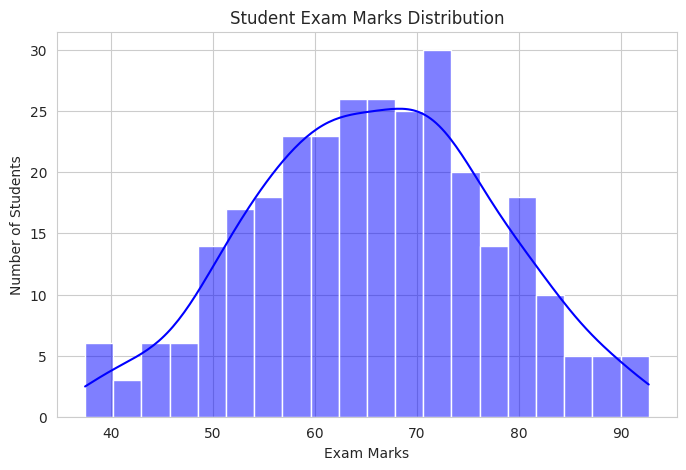

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Exam_Marks"],                       #This graph shows how students' examination marks are distributed
    bins=20,
    kde=True,
    color="blue"
)

plt.title("Student Exam Marks Distribution")
plt.xlabel("Exam Marks")
plt.ylabel("Number of Students")

plt.savefig("Graphs/marks_distribution.png")
plt.show()

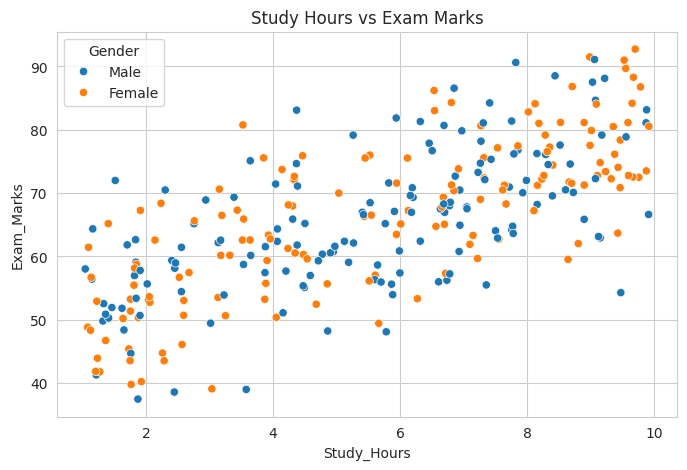

In [ ]:
plt.figure(figsize=(8,5))
                                                           #This graph helps us understand the relationship between study hours and exam marks
sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Exam_Marks",
    hue="Gender"
)

plt.title("Study Hours vs Exam Marks")

plt.savefig("Graphs/study_vs_marks.png")
plt.show()

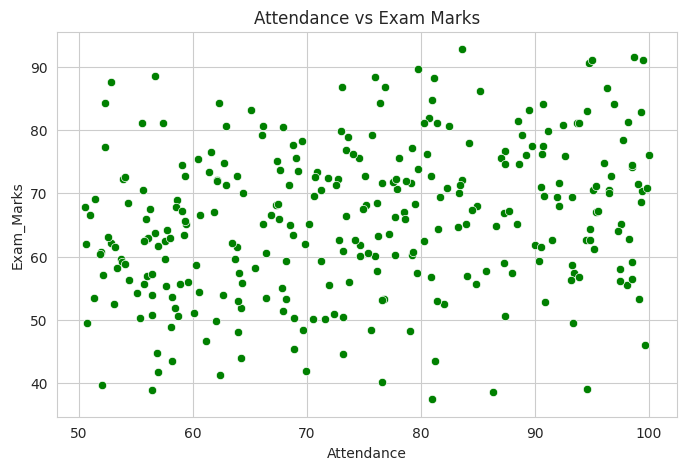

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(                                            #This graph compares student attendance percentage with examination marks
    data=df,
    x="Attendance",
    y="Exam_Marks",
    color="green"
)

plt.title("Attendance vs Exam Marks")

plt.savefig("Graphs/attendance_vs_marks.png")
plt.show()

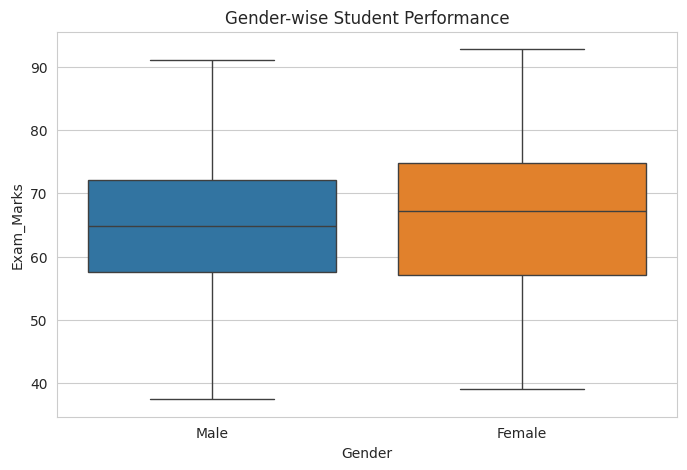

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(                                          #This graph compares the distribution of examination marks across genders
    data=df,
    x="Gender",
    y="Exam_Marks",
    hue="Gender",
    legend=False
)

plt.title("Gender-wise Student Performance")

plt.savefig("Graphs/gender_performance.png")
plt.show()

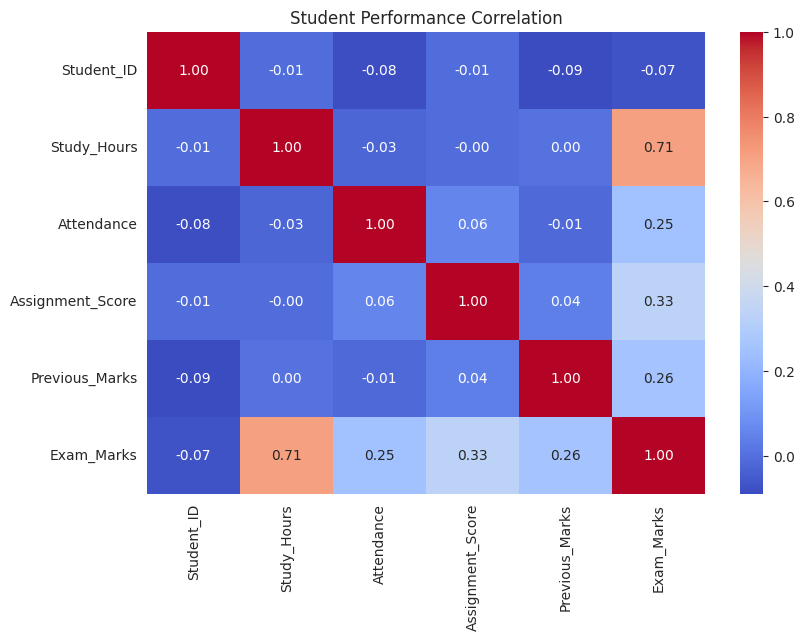

In [ ]:
plt.figure(figsize=(9,6))
                                                             #This graph shows correlations between numerical variables. It helps identify positive and negative relationships."
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Student Performance Correlation")

plt.savefig("Graphs/correlation_heatmap.png")
plt.show()

In [ ]:
average = df["Exam_Marks"].mean()
highest = df["Exam_Marks"].max()
lowest = df["Exam_Marks"].min()

passed = (df["Exam_Marks"] >= 40).sum()
failed = (df["Exam_Marks"] < 40).sum()

print("STUDENT PERFORMANCE REPORT")
print("---------------------------")

print("Total Students:", len(df))
print("Average Marks:", round(average, 2))
print("Highest Marks:", round(highest, 2))
print("Lowest Marks:", round(lowest, 2))
print("Passed Students:", passed)
print("Failed Students:", failed)

STUDENT PERFORMANCE REPORT
---------------------------
Total Students: 300
Average Marks: 65.76
Highest Marks: 92.74
Lowest Marks: 37.49
Passed Students: 295
Failed Students: 5


In [ ]:
prs = Presentation()

slides = [
    ("STUDENT PERFORMANCE ANALYSIS",
     ["EDA using Python",
      "Analysis of academic performance",
      "Python and Data Visualization"]),

    ("INTRODUCTION",
     ["EDA helps analyze student performance",
      "Study hours and attendance are examined",
      "Visualizations help understand data"]),

    ("OBJECTIVES",
     ["Analyze examination marks",
      "Identify performance-related factors",
      "Present insights using graphs"]),

    ("DATASET DESCRIPTION",
     ["Dataset contains 300 students",
      "Includes attendance and study hours",
      "Exam marks are the target variable"]),

    ("DATA PREPROCESSING",
     ["Check missing values",
      "Inspect dataset structure",
      "Calculate statistical summaries"]),

    ("EXAM MARKS DISTRIBUTION",
     ["Understand marks distribution",
      "Identify score patterns",
      "Compare student performance"]),

    ("STUDY HOURS ANALYSIS",
     ["Analyze study hours",
      "Compare study hours with marks",
      "Observe performance patterns"]),

    ("ATTENDANCE ANALYSIS",
     ["Analyze attendance percentage",
      "Compare attendance and exam marks",
      "Understand attendance patterns"]),

    ("CORRELATION ANALYSIS",
     ["Calculate numerical correlations",
      "Visualize relationships using heatmap",
      "Identify associated factors"]),

    ("CONCLUSION",
     ["EDA provides useful academic insights",
      "Graphs help understand performance",
      "Future scope includes prediction"])
]

for title, points in slides:
    slide = prs.slides.add_slide(prs.slide_layouts[6])

    title_box = slide.shapes.add_textbox(
        Inches(0.5), Inches(0.3),
        Inches(12), Inches(0.8)
    )

    p = title_box.text_frame.paragraphs[0]
    p.text = title
    p.font.size = Pt(28)
    p.font.bold = True
    p.font.color.rgb = RGBColor(25, 55, 100)

    body = slide.shapes.add_textbox(
        Inches(0.8), Inches(1.7),
        Inches(11), Inches(4.5)
    )

    tf = body.text_frame

    for i, point in enumerate(points):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        p.text = point
        p.font.size = Pt(23)
        p.space_after = Pt(25)

prs.save("Student_Performance_Analysis_PPT.pptx")

print("PowerPoint created successfully!")

PowerPoint created successfully!


In [ ]:
import shutil
from google.colab import files

# Save graphs and dataset in one folder
os.makedirs("Student_Performance_Project", exist_ok=True)

shutil.copy(
    "student_performance.csv",
    "Student_Performance_Project/"
)

shutil.copytree(
    "Graphs",
    "Student_Performance_Project/Graphs",
    dirs_exist_ok=True
)

shutil.copy(
    "Student_Performance_Analysis_PPT.pptx",
    "Student_Performance_Project/"
)

shutil.make_archive(
    "Student_Performance_Project",
    "zip",
    ".",
    "Student_Performance_Project"
)

files.download("Student_Performance_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>